In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data Analysis and visualization of last 365 days

In [4]:
df365 = pd.read_csv('cleaned_MidBanesworLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,38.878687,µg/m³,2025-11-25 14:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,14:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,44.905125,µg/m³,2025-11-25 15:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,15:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,48.938361,µg/m³,2025-11-25 16:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,16:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,48.021458,µg/m³,2025-11-25 17:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,17:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,49.416167,µg/m³,2025-11-25 18:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2025-11-25,18:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,97.325000,µg/m³,2026-01-06 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,06:45:00
996,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,107.025500,µg/m³,2026-01-06 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,07:45:00
997,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,144.185445,µg/m³,2026-01-06 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,08:45:00
998,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,110.216833,µg/m³,2026-01-06 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-01-06,09:45:00


In [5]:
df365['date'].unique()

<ArrowStringArray>
['2025-11-25', '2025-11-26', '2025-11-27', '2025-11-28', '2025-11-29',
 '2025-11-30', '2025-12-01', '2025-12-02', '2025-12-03', '2025-12-04',
 '2025-12-05', '2025-12-06', '2025-12-07', '2025-12-08', '2025-12-09',
 '2025-12-10', '2025-12-11', '2025-12-12', '2025-12-13', '2025-12-14',
 '2025-12-15', '2025-12-16', '2025-12-17', '2025-12-18', '2025-12-19',
 '2025-12-20', '2025-12-21', '2025-12-22', '2025-12-23', '2025-12-24',
 '2025-12-25', '2025-12-26', '2025-12-27', '2025-12-28', '2025-12-29',
 '2025-12-30', '2025-12-31', '2026-01-01', '2026-01-02', '2026-01-03',
 '2026-01-04', '2026-01-05', '2026-01-06']
Length: 43, dtype: str

In [6]:
# 1. Load hourly data observations
hourly = df365

# Ensure date and PM2.5 values have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [7]:
# 2-3. Aggrigate available hourly PM2.5 values to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        pm25_daily_mean_ug_m3=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [8]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [9]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["pm25_daily_mean_ug_m3"].isna(), "fill_method"] = "missing_long_gap"

In [10]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["pm25_daily_mean_ug_m3"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["pm25_daily_mean_ug_m3"]
            right_value = daily.iloc[last_pos + 1]["pm25_daily_mean_ug_m3"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["pm25_daily_mean_ug_m3"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "pm25_daily_mean_ug_m3"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [11]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")

In [12]:
daily

,date,pm25_daily_mean_ug_m3,hourly_observation_count,fill_method
0,2025-11-25,2025-11-25,10,observed
1,2025-11-26,2025-11-26,24,observed
2,2025-11-27,2025-11-27,24,observed
3,2025-11-28,2025-11-28,24,observed
4,2025-11-29,2025-11-29,24,observed
5,2025-11-30,2025-11-30,24,observed
6,2025-12-01,2025-12-01,23,observed
7,2025-12-02,2025-12-02,24,observed
8,2025-12-03,2025-12-03,24,observed
9,2025-12-04,2025-12-04,24,observed


In [13]:
daily.columns

Index(['date', 'pm25_daily_mean_ug_m3', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

/tmp/ipykernel_17803/1174245757.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


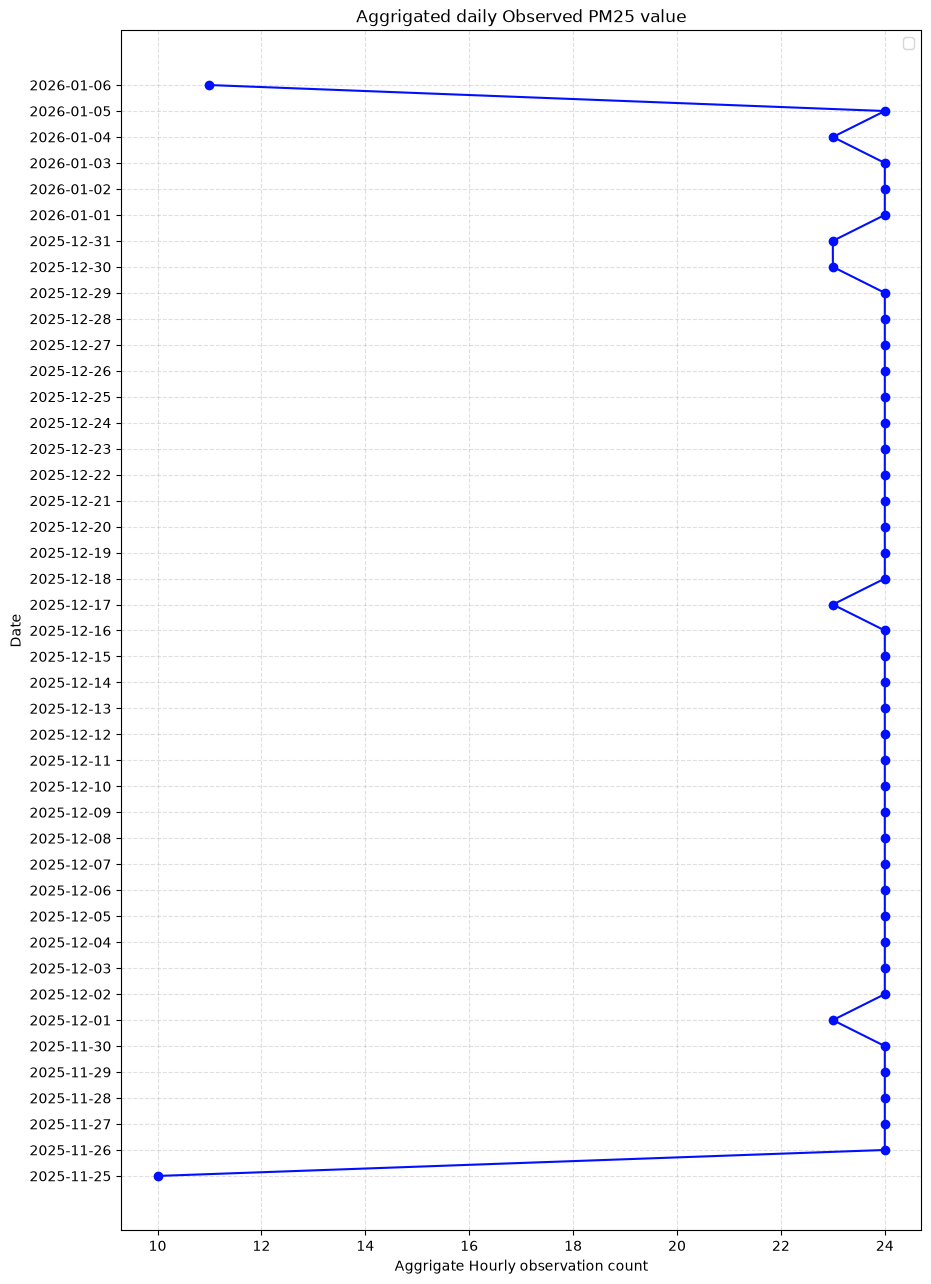

In [14]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed PM25 value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and visualization of last 30 days

In [26]:
df30 = pd.read_csv('cleaned_MidBanesworLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,24.1,µg/m³,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,06:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,26.3,µg/m³,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,07:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,30.4,µg/m³,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,08:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,23.1,µg/m³,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,09:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,27.7,µg/m³,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,38.0,µg/m³,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
716,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,43.7,µg/m³,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
717,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,40.5,µg/m³,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
718,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,35.7,µg/m³,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [27]:
df30['date'].unique

<bound method Series.unique of 0      2026-09-12
1      2026-09-12
2      2026-09-12
3      2026-09-12
4      2026-09-12
          ...    
715    2026-10-12
716    2026-10-12
717    2026-10-12
718    2026-10-12
719    2026-10-12
Name: date, Length: 720, dtype: str>

In [28]:
# 1. Load hourly data observations
hourly = df30

# Ensure date and PM2.5 values have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [30]:
# 2-3. Aggrigate available hourly PM2.5 values to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        pm25_daily_mean_ug_m3=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [32]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [33]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["pm25_daily_mean_ug_m3"].isna(), "fill_method"] = "missing_long_gap"

In [34]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["pm25_daily_mean_ug_m3"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["pm25_daily_mean_ug_m3"]
            right_value = daily.iloc[last_pos + 1]["pm25_daily_mean_ug_m3"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["pm25_daily_mean_ug_m3"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "pm25_daily_mean_ug_m3"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [35]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")

In [36]:
daily

,date,pm25_daily_mean_ug_m3,hourly_observation_count,fill_method
0,2026-09-12,2026-09-12,18,observed
1,2026-09-13,2026-09-13,24,observed
2,2026-09-14,2026-09-14,24,observed
3,2026-09-15,2026-09-15,24,observed
4,2026-09-16,2026-09-16,24,observed
5,2026-09-17,2026-09-17,24,observed
6,2026-09-18,2026-09-18,24,observed
7,2026-09-19,2026-09-19,24,observed
8,2026-09-20,2026-09-20,24,observed
9,2026-09-21,2026-09-21,24,observed


In [37]:
daily.columns

Index(['date', 'pm25_daily_mean_ug_m3', 'hourly_observation_count',
       'fill_method'],
      dtype='str')

/tmp/ipykernel_17803/18109499.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


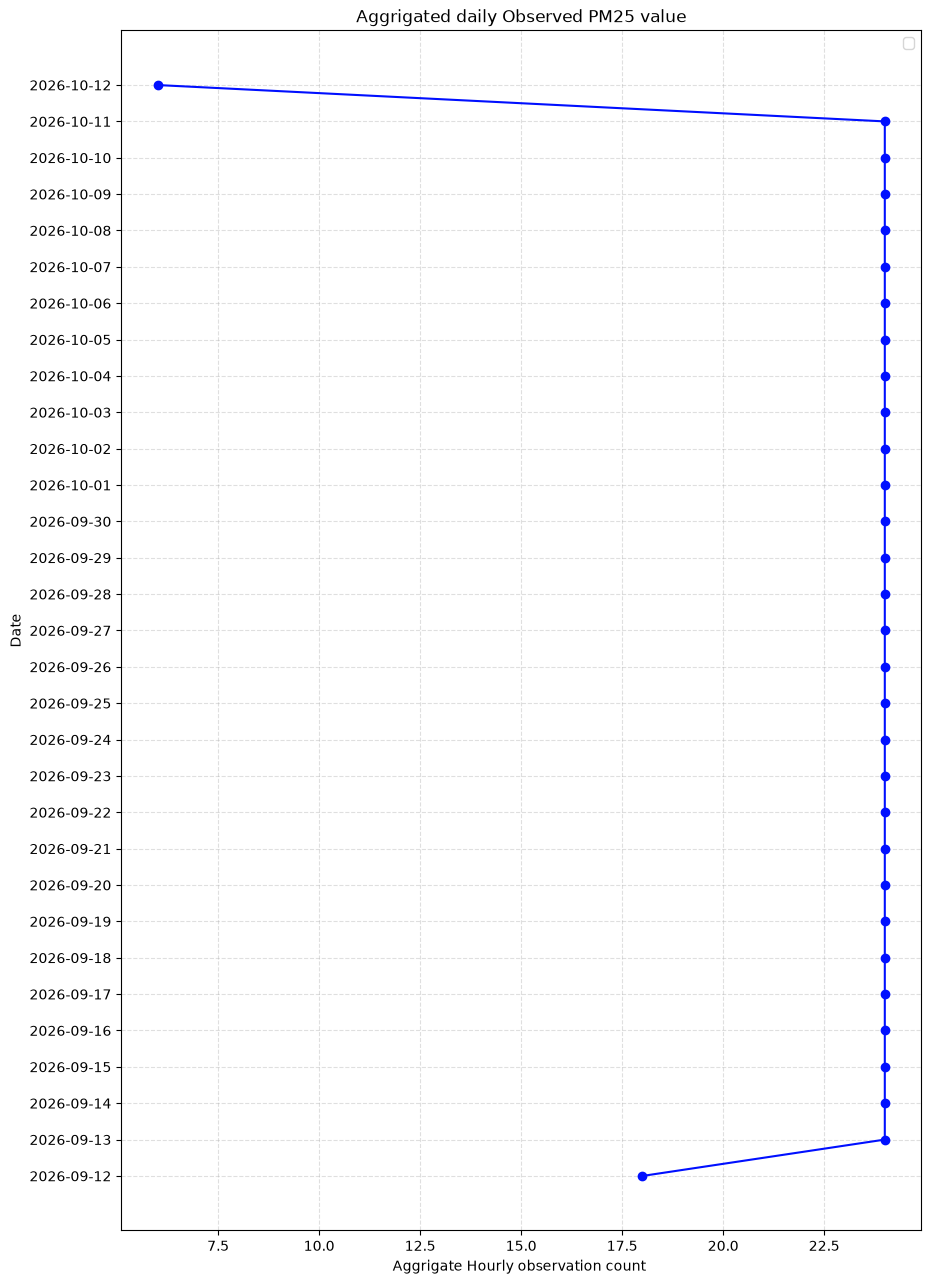

In [38]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed PM25 value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 7 days

In [39]:
df7 = pd.read_csv('cleaned_MidBanesworLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,50.7,µg/m³,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,54.2,µg/m³,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,55.4,µg/m³,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,57.9,µg/m³,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,56.7,µg/m³,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,38.0,µg/m³,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
164,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,43.7,µg/m³,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
165,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,40.5,µg/m³,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
166,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,35.7,µg/m³,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [40]:
df7['date'].unique()

<ArrowStringArray>
['2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08', '2026-10-09',
 '2026-10-10', '2026-10-11', '2026-10-12']
Length: 8, dtype: str

In [41]:
# 1. Load hourly data observations
hourly = df7

# Ensure date and PM2.5 values have appropriate types
hourly['date'] = pd.to_datetime(hourly['date'])
hourly['value'] = pd.to_numeric(hourly['value'], errors='coerce')

In [42]:
# 2-3. Aggrigate available hourly PM2.5 values to daily means
daily = (
    hourly.dropna(subset=['date', 'value'])
    .groupby('date', as_index=True)
    .agg(
        pm25_daily_mean_ug_m3=('date', 'mean'),
        hourly_observation_count=('value', 'count'),
    )
    .sort_index()
)

In [43]:
# 4. Include every calendar day in the observed date range
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days)
daily.index.name = "date"

In [44]:
# Mark original observed daily means
daily["fill_method"] = "observed"
daily.loc[daily["pm25_daily_mean_ug_m3"].isna(), "fill_method"] = "missing_long_gap"

In [45]:
# 5–6. Identify missing runs and interpolate only 1–2 day gaps
missing = daily["pm25_daily_mean_ug_m3"].isna()
run_id = missing.ne(missing.shift()).cumsum()

for _, run_mask in missing.groupby(run_id):
    if not run_mask.iloc[0]:
        continue  # This run contains observed data, not missing data

    gap_dates = run_mask.index[run_mask]
    gap_length = len(gap_dates)

    # Only fill gaps lasting one or two days and bounded by observed values
    if gap_length in (1, 2):
        first_pos = daily.index.get_loc(gap_dates[0])
        last_pos = daily.index.get_loc(gap_dates[-1])

        has_left_neighbor = first_pos > 0
        has_right_neighbor = last_pos < len(daily.index) - 1

        if has_left_neighbor and has_right_neighbor:
            left_value = daily.iloc[first_pos - 1]["pm25_daily_mean_ug_m3"]
            right_value = daily.iloc[last_pos + 1]["pm25_daily_mean_ug_m3"]

            if pd.notna(left_value) and pd.notna(right_value):
                # Linear interpolation between the two surrounding daily means
                interpolated = daily["pm25_daily_mean_ug_m3"].interpolate(
                    method="linear",
                    limit=2,
                    limit_area="inside",
                )
                daily.loc[gap_dates, "pm25_daily_mean_ug_m3"] = interpolated.loc[gap_dates]
                daily.loc[gap_dates, "hourly_observation_count"] = 0
                daily.loc[gap_dates, "fill_method"] = "linear_interpolation"

In [46]:
# 7. Write a tidy CSV
daily = daily.reset_index()
daily["date"] = daily["date"].dt.strftime("%Y-%m-%d")

In [47]:
daily

,date,pm25_daily_mean_ug_m3,hourly_observation_count,fill_method
0,2026-10-05,2026-10-05,18,observed
1,2026-10-06,2026-10-06,24,observed
2,2026-10-07,2026-10-07,24,observed
3,2026-10-08,2026-10-08,24,observed
4,2026-10-09,2026-10-09,24,observed
5,2026-10-10,2026-10-10,24,observed
6,2026-10-11,2026-10-11,24,observed
7,2026-10-12,2026-10-12,6,observed


/tmp/ipykernel_17803/1788375289.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


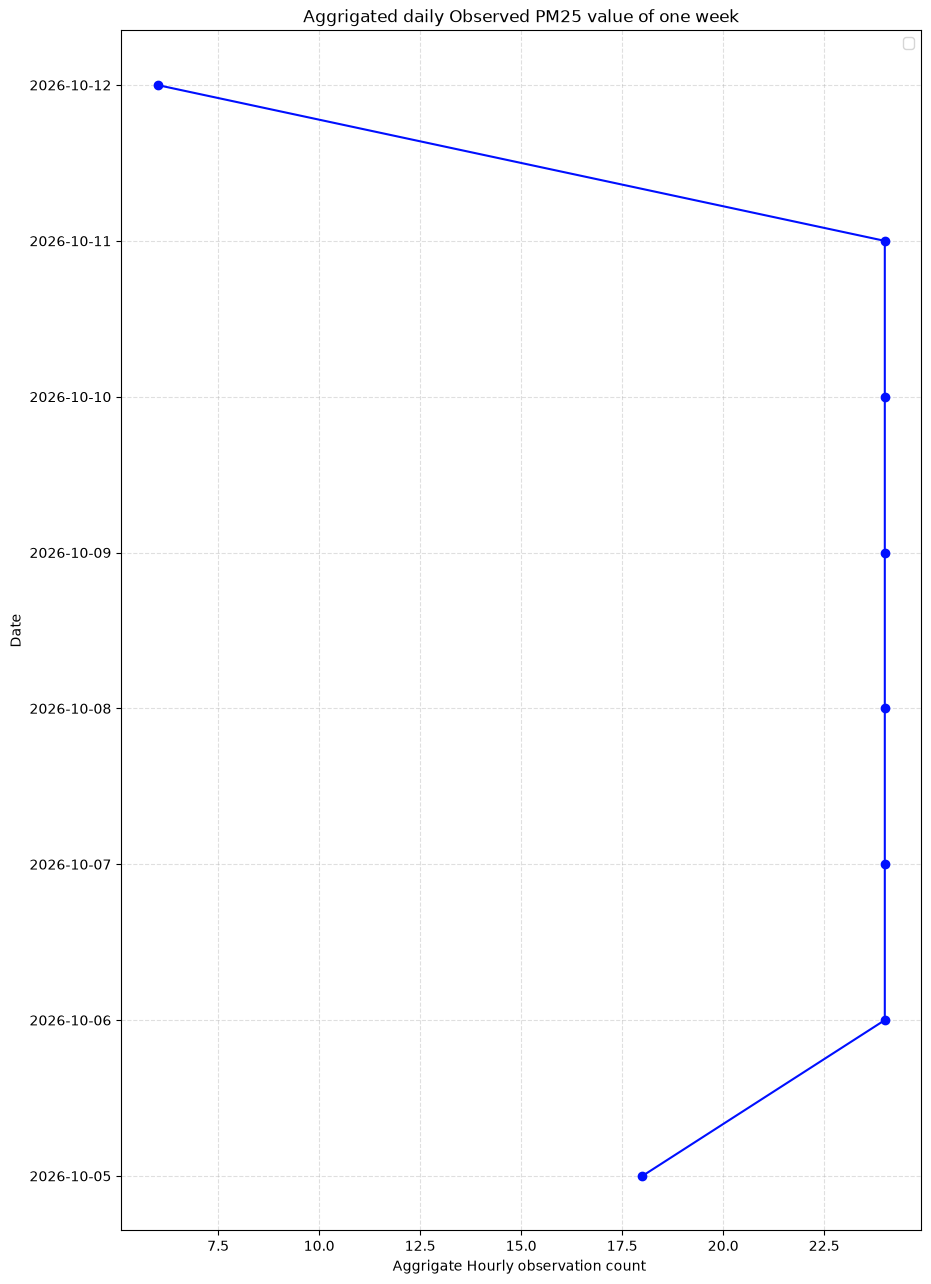

In [48]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily['hourly_observation_count'], daily['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed PM25 value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [49]:
df24 = pd.read_csv('cleaned_MidBanesworLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,42.6,µg/m³,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,46.5,µg/m³,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,47.8,µg/m³,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,41.6,µg/m³,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,37.6,µg/m³,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,39.9,µg/m³,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,34.6,µg/m³,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,24.7,µg/m³,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,23.1,µg/m³,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,6142022,Mid Baneshwor (SC-39)-GD Labs,pm25,24.0,µg/m³,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.693662,85.340501,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


In [50]:
df24['time'].unique

<bound method Series.unique of 0     06:45:00
1     07:45:00
2     08:45:00
3     09:45:00
4     10:45:00
5     11:45:00
6     12:45:00
7     13:45:00
8     14:45:00
9     15:45:00
10    16:45:00
11    17:45:00
12    18:45:00
13    19:45:00
14    20:45:00
15    21:45:00
16    22:45:00
17    23:45:00
18    00:45:00
19    01:45:00
20    02:45:00
21    03:45:00
22    04:45:00
23    05:45:00
Name: time, dtype: str>

/tmp/ipykernel_17803/1789865348.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


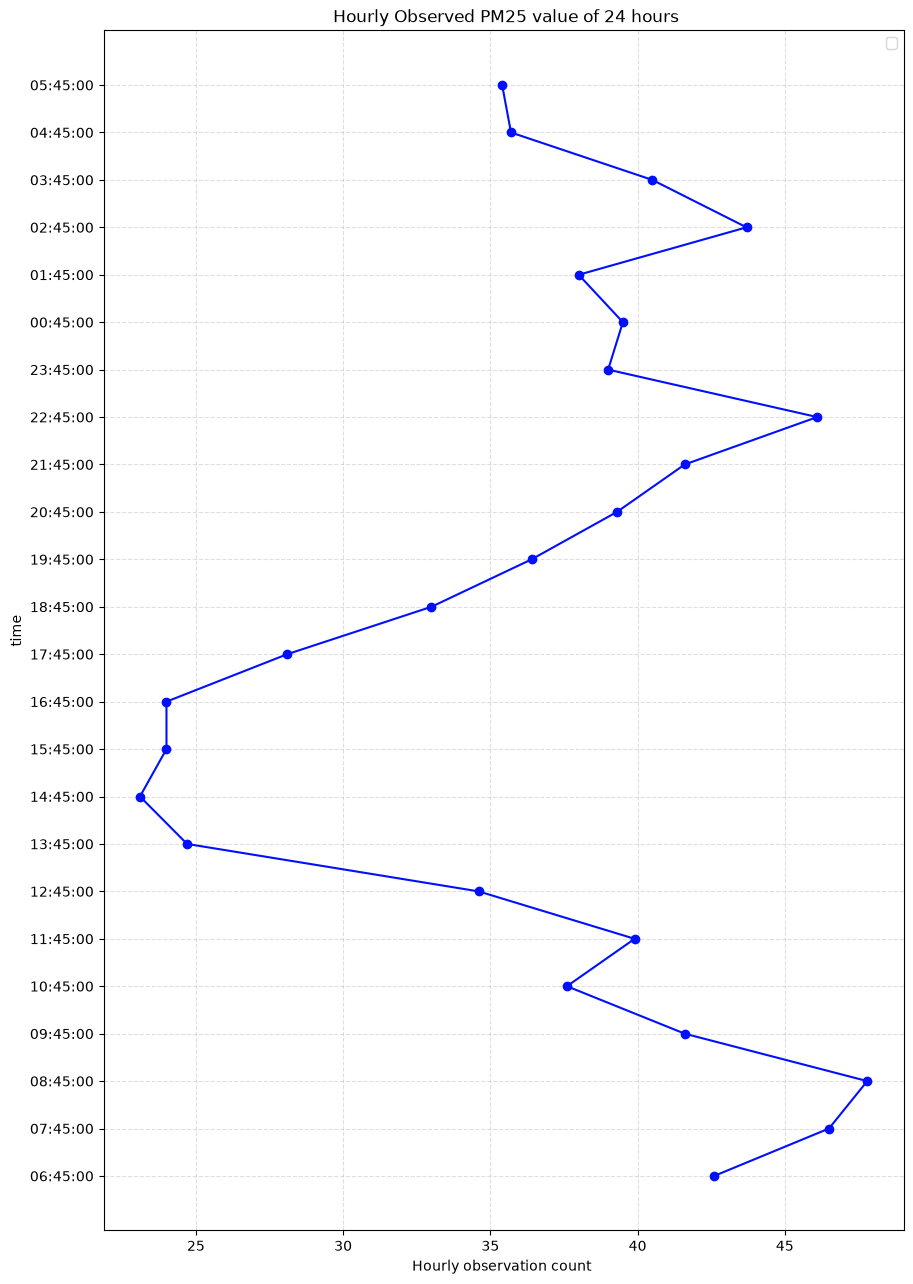

In [51]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(df24['value'], df24['time'], color ='#000fff', marker='o')
plt.xlabel('Hourly observation count ')
plt.ylabel('time')
plt.title(" Hourly Observed PM25 value of 24 hours")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()